<a href="https://colab.research.google.com/github/jar7is/game-board-pattern-generator-Toolkit/blob/main/game_board_pattern_generator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎮 Project 5: Game Board & Pattern Generator Toolkit
### Using Python + NumPy | Beginner-Friendly | Google Colab

---

## 📋 Section 1: Project Introduction

Welcome to the **Game Board & Pattern Generator Toolkit**! 🎉

In this project, we will:
- 🏁 Build game boards (Tic-Tac-Toe, Checkerboard) using NumPy arrays
- 🔷 Generate diagonal and anti-diagonal patterns
- ♟️ Place and move pieces using array indexing
- 🏆 Detect wins, draws, and game states automatically
- 🎨 Visualize everything using Matplotlib

### 🎯 What You Will Learn
| Concept | Where Used |
|---|---|
| `np.zeros()` | Create empty boards |
| `np.ones()` | Fill boards with values |
| `np.full()` | Create boards with custom fill |
| `np.eye()` | Diagonal patterns |
| `np.arange()` | Index arrays for fancy indexing |
| Nested list → array | Board setup |
| Slicing & stepped slicing | Checkerboard pattern |
| Fancy indexing | Piece placement |
| `np.fliplr()` | Anti-diagonal pattern |
| `np.all()` and conditional statements | Win detection |

### 👩‍💻 Skill Level
**Beginner** – No prior NumPy experience needed!

> 💡 **Tip:** Run each cell one by one using `Shift + Enter` in Google Colab.

---
## 📦 Section 2: Importing Libraries

Before we start coding, we need to import the tools (libraries) we'll use.

- **NumPy**: Handles all our array/matrix operations (the backbone of this project)
- **Matplotlib**: Draws and displays game boards as colorful images

> 💡 In Google Colab, NumPy and Matplotlib are already pre-installed. No need to `pip install`!

In [1]:
# ─── Cell 2: Import Required Libraries ───────────────────────────────────────

import numpy as np                        # NumPy for array operations
import matplotlib.pyplot as plt           # Matplotlib for visualizations
import matplotlib.colors as mcolors       # For custom color maps
import warnings
warnings.filterwarnings('ignore')         # Suppress minor warnings

# Set a consistent dark style for all plots
plt.rcParams['figure.facecolor'] = '#1a1a2e'
plt.rcParams['axes.facecolor']   = '#16213e'
plt.rcParams['text.color']       = 'white'
plt.rcParams['axes.labelcolor']  = 'white'
plt.rcParams['xtick.color']      = 'white'
plt.rcParams['ytick.color']      = 'white'

print('✅ Libraries imported successfully!')
print(f'   NumPy version     : {np.__version__}')
print(f'   Matplotlib version: {plt.matplotlib.__version__}')

✅ Libraries imported successfully!
   NumPy version     : 2.1.3
   Matplotlib version: 3.10.0


---
## 🧠 Section 3: Understanding NumPy Arrays

Before jumping into game boards, let's understand the core NumPy tools we'll use.

Think of a NumPy array as a **super-powered table (grid) of numbers**.

| Function | What It Does | Example Use |
|---|---|---|
| `np.zeros((r,c))` | Grid filled with **0s** | Empty board |
| `np.ones((r,c))` | Grid filled with **1s** | Filled board |
| `np.full((r,c), v)` | Grid filled with value **v** | Pre-set board |
| `np.eye(n)` | **Identity matrix** (1s on diagonal) | Diagonal patterns |
| `np.arange(n)` | Range array [0,1,...,n-1] | Index arrays |

In [2]:
# ─── Cell 3A: NumPy Array Creation Functions ─────────────────────────────────

print('=' * 55)
print('  🔢 NumPy Array Creation – Quick Tour')
print('=' * 55)

# np.zeros() ── Creates an array filled entirely with 0s
# WHY: Represents empty game board cells
zeros_board = np.zeros((3, 3), dtype=int)
print('\n📌 np.zeros((3,3), dtype=int)  →  Empty board:')
print(zeros_board)

# np.ones() ── Creates an array filled entirely with 1s
# WHY: Useful for marking all cells or math operations
ones_board = np.ones((3, 3), dtype=int)
print('\n📌 np.ones((3,3), dtype=int)   →  All-ones board:')
print(ones_board)

# np.full() ── Creates an array filled with a custom value
# WHY: Pre-fill boards with any sentinel value you choose
full_board = np.full((3, 3), fill_value=9, dtype=int)
print('\n📌 np.full((3,3), fill_value=9) →  Board filled with 9s:')
print(full_board)

# np.eye() ── Creates an identity matrix with 1s on the main diagonal
# WHY: Perfect for generating diagonal patterns
eye_matrix = np.eye(4, dtype=int)
print('\n📌 np.eye(4, dtype=int)         →  4×4 Identity matrix:')
print(eye_matrix)

# np.arange() ── Creates sequential integers [0, 1, 2, ..., n-1]
# WHY: Used to build index arrays for fancy indexing
index_array = np.arange(6)
print('\n📌 np.arange(6)                 →  Range array:')
print(index_array)

print('\n✅ NumPy array creation demonstrated!')

  🔢 NumPy Array Creation – Quick Tour

📌 np.zeros((3,3), dtype=int)  →  Empty board:
[[0 0 0]
 [0 0 0]
 [0 0 0]]

📌 np.ones((3,3), dtype=int)   →  All-ones board:
[[1 1 1]
 [1 1 1]
 [1 1 1]]

📌 np.full((3,3), fill_value=9) →  Board filled with 9s:
[[9 9 9]
 [9 9 9]
 [9 9 9]]

📌 np.eye(4, dtype=int)         →  4×4 Identity matrix:
[[1 0 0 0]
 [0 1 0 0]
 [0 0 1 0]
 [0 0 0 1]]

📌 np.arange(6)                 →  Range array:
[0 1 2 3 4 5]

✅ NumPy array creation demonstrated!


In [3]:
# ─── Cell 3B: Slicing, Stepped Slicing & Fancy Indexing ──────────────────────

print('=' * 55)
print('  ✂️  Slicing and Fancy Indexing – Quick Tour')
print('=' * 55)

sample = np.arange(9).reshape(3, 3)   # 3×3 grid with values 0-8
print('\nSample 3×3 grid (values 0–8):')
print(sample)

# Basic slicing: board[row_start:row_stop, col_start:col_stop]
print('\n📌 Basic slice – Top-left 2×2  →  sample[0:2, 0:2]:')
print(sample[0:2, 0:2])

# Stepped slicing: picks every 2nd row AND every 2nd column
# syntax: [start::step, start::step]
print('\n📌 Stepped slice – Every 2nd row & col  →  sample[::2, ::2]:')
print(sample[::2, ::2])

# Fancy indexing: pick specific (row, col) pairs using index arrays
rows = np.array([0, 2])    # Select row 0 and row 2
cols = np.array([0, 2])    # Select col 0 and col 2
print(f'\n📌 Fancy indexing – Corners  →  sample[{list(rows)}, {list(cols)}]:')
print(f'   Picks: (row0,col0) and (row2,col2) = {sample[rows, cols]}')

print('\n✅ Slicing and indexing demonstrated!')

  ✂️  Slicing and Fancy Indexing – Quick Tour

Sample 3×3 grid (values 0–8):
[[0 1 2]
 [3 4 5]
 [6 7 8]]

📌 Basic slice – Top-left 2×2  →  sample[0:2, 0:2]:
[[0 1]
 [3 4]]

📌 Stepped slice – Every 2nd row & col  →  sample[::2, ::2]:
[[0 2]
 [6 8]]

📌 Fancy indexing – Corners  →  sample[[np.int64(0), np.int64(2)], [np.int64(0), np.int64(2)]]:
   Picks: (row0,col0) and (row2,col2) = [0 8]

✅ Slicing and indexing demonstrated!


---
## ❌⭕ Section 4: Tic-Tac-Toe Board Generator

### 🧩 Board Encoding
We represent the board as a **3×3 NumPy integer array**:

| Value | Meaning |
|:---:|---|
| `0` | Empty cell |
| `1` | Player **X** |
| `-1` | Player **O** |

Using integers allows fast NumPy math for win-checking.

We create the board two ways:
1. **`np.zeros()`** – most common technique
2. **Nested Python list → `np.array()`** – demonstrates list conversion

In [4]:
# ─── Cell 4A: Board Creation ──────────────────────────────────────────────────

def display_board_text(board, title='Tic-Tac-Toe Board'):
    """
    Displays the 3×3 board as readable text.
    0 → '.'  |  1 → 'X'  |  -1 → 'O'
    """
    symbol_map = {0: '.', 1: 'X', -1: 'O'}
    print(f'\n  ── {title} ──')
    print('      Col: 0   1   2')
    for row_idx, row in enumerate(board):
        row_str = ' | '.join(symbol_map[cell] for cell in row)
        print(f'    Row {row_idx}: {row_str}')
    print()


# ── Method 1: np.zeros() ──────────────────────────────────────────────────────
# Creates a 3×3 grid filled with 0s (empty cells)
# dtype=int ensures integer type (not float)
empty_board = np.zeros((3, 3), dtype=int)
print('Method 1: np.zeros((3,3), dtype=int)')
print(empty_board)
print(f'Shape: {empty_board.shape}  |  dtype: {empty_board.dtype}')
display_board_text(empty_board, 'Empty Board')


# ── Method 2: Nested Python list → np.array() ────────────────────────────────
# Each inner list is one row of the board
# 1=X, -1=O, 0=empty
nested_list_board = [
    [ 1,  0, -1],   # Row 0: X _ O
    [ 0,  1,  0],   # Row 1: _ X _
    [-1,  0,  0]    # Row 2: O _ _
]

# np.array() converts the nested list into a proper NumPy array
sample_board = np.array(nested_list_board, dtype=int)
print('Method 2: np.array(nested_list)')
print(sample_board)
print(f'Shape: {sample_board.shape}  |  dtype: {sample_board.dtype}')
display_board_text(sample_board, 'Sample Board from Nested List')

print('✅ Both board creation methods demonstrated!')

Method 1: np.zeros((3,3), dtype=int)
[[0 0 0]
 [0 0 0]
 [0 0 0]]
Shape: (3, 3)  |  dtype: int64

  ── Empty Board ──
      Col: 0   1   2
    Row 0: . | . | .
    Row 1: . | . | .
    Row 2: . | . | .

Method 2: np.array(nested_list)
[[ 1  0 -1]
 [ 0  1  0]
 [-1  0  0]]
Shape: (3, 3)  |  dtype: int64

  ── Sample Board from Nested List ──
      Col: 0   1   2
    Row 0: X | . | O
    Row 1: . | X | .
    Row 2: O | . | .

✅ Both board creation methods demonstrated!


🎨 Visualizing the Sample Board:


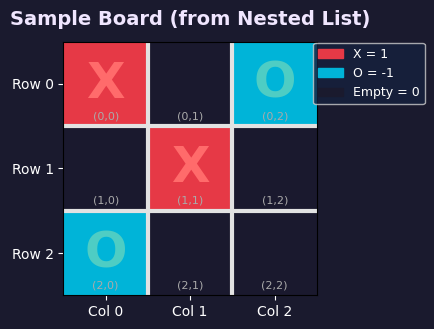

In [5]:
# ─── Cell 4B: Visual Board Display with Matplotlib ───────────────────────────

def visualize_ttt_board(board, title='Tic-Tac-Toe Board'):
    """
    Draws the Tic-Tac-Toe board as a colorful image.
    Colors: Red=X, Teal=O, Dark Blue=Empty
    """
    from matplotlib.patches import Patch

    fig, ax = plt.subplots(figsize=(5, 5), facecolor='#1a1a2e')
    ax.set_facecolor('#0f3460')

    cmap = mcolors.LinearSegmentedColormap.from_list(
        'ttt', ['#00b4d8', '#1a1a2e', '#e63946'], N=3
    )
    ax.imshow(board, cmap=cmap, vmin=-1, vmax=1, aspect='equal')

    # Draw grid lines
    for x in [0.5, 1.5]:
        ax.axhline(x, color='#e2e2e2', linewidth=3)
        ax.axvline(x, color='#e2e2e2', linewidth=3)

    symbol_map = {0: '', 1: 'X', -1: 'O'}
    color_map  = {0: 'white', 1: '#ff6b6b', -1: '#4ecdc4'}

    # Annotate each cell with its symbol and (row,col) index
    for r in range(3):
        for c in range(3):
            val = board[r, c]
            sym = symbol_map[val]
            if sym:
                ax.text(c, r, sym, ha='center', va='center',
                        fontsize=36, fontweight='bold', color=color_map[val])
            ax.text(c, r + 0.38, f'({r},{c})',
                    ha='center', va='center', fontsize=8, color='#aaaaaa')

    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xticklabels(['Col 0', 'Col 1', 'Col 2'], color='white', fontsize=10)
    ax.set_yticklabels(['Row 0', 'Row 1', 'Row 2'], color='white', fontsize=10)
    ax.set_title(title, color='#f0e6ff', fontsize=14, fontweight='bold', pad=12)

    legend = [
        Patch(color='#e63946', label='X = 1'),
        Patch(color='#00b4d8', label='O = -1'),
        Patch(color='#1a1a2e', label='Empty = 0'),
    ]
    ax.legend(handles=legend, loc='upper right', bbox_to_anchor=(1.45, 1.02),
              facecolor='#16213e', labelcolor='white', fontsize=9)

    plt.tight_layout()
    plt.show()


print('🎨 Visualizing the Sample Board:')
visualize_ttt_board(sample_board, 'Sample Board (from Nested List)')

---
## ♟️ Section 5: 8×8 Checkerboard Generator

A checkerboard has alternating dark and light squares.

### 🧠 The Key Trick: Stepped Slicing

```python
board[::2, ::2]   # Rows 0,2,4,6  AND  Cols 0,2,4,6  → even+even
board[1::2, 1::2] # Rows 1,3,5,7  AND  Cols 1,3,5,7  → odd+odd
```

Setting both groups to `1` creates the alternating pattern:
- `0` = dark square
- `1` = light square

8×8 Checkerboard (NumPy Array):
[[1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]]
Shape: (8, 8)
Light squares (1): 32
Dark  squares (0): 32


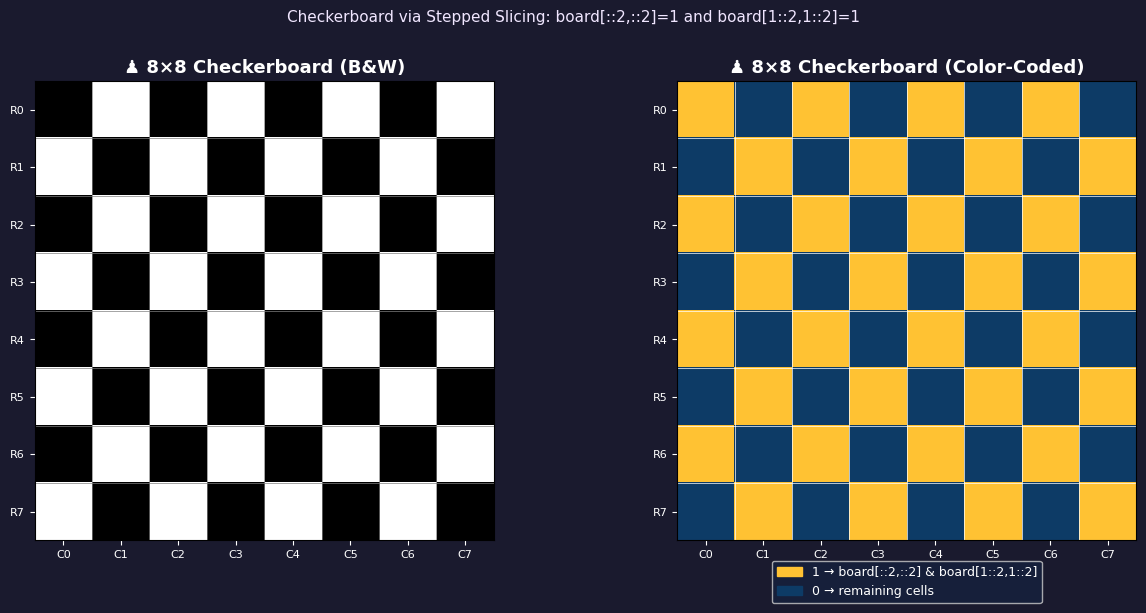

✅ Checkerboard generated!


In [6]:
# ─── Cell 5: 8×8 Checkerboard Generator ─────────────────────────────────────

def generate_checkerboard(size=8):
    """
    Generates an n×n checkerboard using NumPy stepped slicing.

    Algorithm:
      1. Start with all-zeros board
      2. board[::2,  ::2]  = 1  ← even rows, even cols
      3. board[1::2, 1::2] = 1  ← odd  rows, odd  cols
    """
    # Step 1: Create empty n×n board filled with 0s
    board = np.zeros((size, size), dtype=int)

    # Step 2: Set (even row, even col) cells to 1
    # [::2, ::2] → rows 0,2,4,6 AND cols 0,2,4,6
    board[::2, ::2] = 1

    # Step 3: Set (odd row, odd col) cells to 1
    # [1::2, 1::2] → rows 1,3,5,7 AND cols 1,3,5,7
    board[1::2, 1::2] = 1

    return board


checkerboard = generate_checkerboard(8)

print('8×8 Checkerboard (NumPy Array):')
print(checkerboard)
print(f'Shape: {checkerboard.shape}')
print(f'Light squares (1): {np.sum(checkerboard == 1)}')
print(f'Dark  squares (0): {np.sum(checkerboard == 0)}')

# ── Visualization ─────────────────────────────────────────────────────────────
from matplotlib.patches import Patch
fig, axes = plt.subplots(1, 2, figsize=(13, 6), facecolor='#1a1a2e')

# Classic black-and-white
ax1 = axes[0]
ax1.imshow(checkerboard, cmap='binary', aspect='equal')
ax1.set_title('♟️ 8×8 Checkerboard (B&W)', color='white', fontsize=13, fontweight='bold')
ax1.set_xticks(range(8))
ax1.set_yticks(range(8))
ax1.set_xticklabels([f'C{i}' for i in range(8)], color='white', fontsize=8)
ax1.set_yticklabels([f'R{i}' for i in range(8)], color='white', fontsize=8)
for i in range(9):
    ax1.axhline(i - 0.5, color='gray', linewidth=0.5)
    ax1.axvline(i - 0.5, color='gray', linewidth=0.5)

# Color-coded to show stepped slicing regions
ax2 = axes[1]
cmap_color = mcolors.LinearSegmentedColormap.from_list('checker', ['#0d3b66', '#ffc233'], N=2)
ax2.imshow(checkerboard, cmap=cmap_color, aspect='equal')
ax2.set_title('♟️ 8×8 Checkerboard (Color-Coded)', color='white', fontsize=13, fontweight='bold')
ax2.set_xticks(range(8))
ax2.set_yticks(range(8))
ax2.set_xticklabels([f'C{i}' for i in range(8)], color='white', fontsize=8)
ax2.set_yticklabels([f'R{i}' for i in range(8)], color='white', fontsize=8)
for i in range(9):
    ax2.axhline(i - 0.5, color='white', linewidth=0.5)
    ax2.axvline(i - 0.5, color='white', linewidth=0.5)

legend = [Patch(color='#ffc233', label='1 → board[::2,::2] & board[1::2,1::2]'),
          Patch(color='#0d3b66', label='0 → remaining cells')]
ax2.legend(handles=legend, loc='lower center', bbox_to_anchor=(0.5, -0.15),
           facecolor='#16213e', labelcolor='white', fontsize=9)

plt.suptitle('Checkerboard via Stepped Slicing: board[::2,::2]=1 and board[1::2,1::2]=1',
             color='#f0e6ff', fontsize=11, y=1.01)
plt.tight_layout()
plt.show()
print('✅ Checkerboard generated!')

---
## 📐 Section 6: Diagonal and Anti-Diagonal Patterns

### 🔷 Main Diagonal
Runs **top-left → bottom-right**. Generated by `np.eye(n)` which places `1`s where `row == col`.

### 🔶 Anti-Diagonal
Runs **top-right → bottom-left**. Generated by `np.fliplr()` which **mirrors** the array horizontally.
- `fliplr` = **fl**ip **l**eft-**r**ight

### 📍 Index Relationships
| Pattern | Position Formula | Example (n=3) |
|---|---|---|
| Main diagonal | `board[i, i]` | (0,0), (1,1), (2,2) |
| Anti-diagonal | `board[i, n-1-i]` | (0,2), (1,1), (2,0) |

Main Diagonal (np.eye(6)):
[[1 0 0 0 0 0]
 [0 1 0 0 0 0]
 [0 0 1 0 0 0]
 [0 0 0 1 0 0]
 [0 0 0 0 1 0]
 [0 0 0 0 0 1]]
1s at positions: [(np.int64(0), np.int64(0)), (np.int64(1), np.int64(1)), (np.int64(2), np.int64(2)), (np.int64(3), np.int64(3)), (np.int64(4), np.int64(4)), (np.int64(5), np.int64(5))]

Anti-Diagonal (np.fliplr(np.eye(6))):
[[0 0 0 0 0 1]
 [0 0 0 0 1 0]
 [0 0 0 1 0 0]
 [0 0 1 0 0 0]
 [0 1 0 0 0 0]
 [1 0 0 0 0 0]]
1s at positions: [(np.int64(0), np.int64(5)), (np.int64(1), np.int64(4)), (np.int64(2), np.int64(3)), (np.int64(3), np.int64(2)), (np.int64(4), np.int64(1)), (np.int64(5), np.int64(0))]

Both Diagonals Combined (clipped 0–1):
[[1 0 0 0 0 1]
 [0 1 0 0 1 0]
 [0 0 1 1 0 0]
 [0 0 1 1 0 0]
 [0 1 0 0 1 0]
 [1 0 0 0 0 1]]


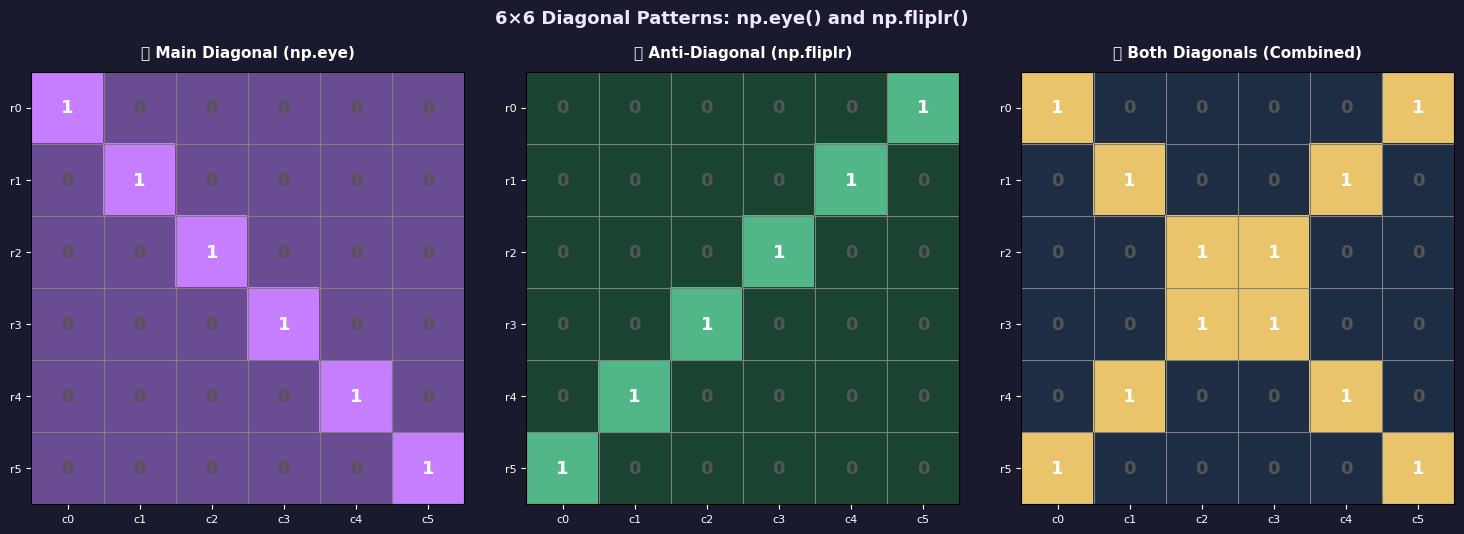

✅ Diagonal patterns generated!


In [7]:
# ─── Cell 6: Diagonal and Anti-Diagonal Patterns ─────────────────────────────

SIZE = 6   # 6×6 grid for clear visualization

# ── Main Diagonal ─────────────────────────────────────────────────────────────
# np.eye(n) creates identity matrix: 1s where row_index == col_index
diagonal = np.eye(SIZE, dtype=int)
print(f'Main Diagonal (np.eye({SIZE})):')
print(diagonal)
print(f'1s at positions: {list(zip(*np.where(diagonal == 1)))}')

# ── Anti-Diagonal ─────────────────────────────────────────────────────────────
# np.fliplr() flips the matrix LEFT ↔ RIGHT (mirrors each row)
# This moves 1s from [i,i] to [i, n-1-i] → anti-diagonal
anti_diagonal = np.fliplr(diagonal)
print(f'\nAnti-Diagonal (np.fliplr(np.eye({SIZE}))):')
print(anti_diagonal)
print(f'1s at positions: {list(zip(*np.where(anti_diagonal == 1)))}')

# ── Combined: Both diagonals ──────────────────────────────────────────────────
# np.clip() caps values at 1 (avoids 2 at center when SIZE is odd)
combined = np.clip(diagonal + anti_diagonal, 0, 1)
print(f'\nBoth Diagonals Combined (clipped 0–1):')
print(combined)

# ── Visualization ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5), facecolor='#1a1a2e')

patterns = [
    (diagonal,      '🔷 Main Diagonal (np.eye)',         '#6a4c93', '#c77dff'),
    (anti_diagonal, '🔶 Anti-Diagonal (np.fliplr)',      '#1b4332', '#52b788'),
    (combined,      '💠 Both Diagonals (Combined)',      '#1d2d44', '#e9c46a'),
]

for ax, (matrix, title, bg, fg) in zip(axes, patterns):
    cmap_p = mcolors.LinearSegmentedColormap.from_list('pat', [bg, fg], N=2)
    ax.imshow(matrix, cmap=cmap_p, aspect='equal', vmin=0, vmax=1)

    for r in range(SIZE):
        for c in range(SIZE):
            val = matrix[r, c]
            ax.text(c, r, str(val), ha='center', va='center',
                    fontsize=13, fontweight='bold',
                    color='white' if val == 1 else '#555555')

    for i in range(SIZE + 1):
        ax.axhline(i - 0.5, color='gray', linewidth=0.8)
        ax.axvline(i - 0.5, color='gray', linewidth=0.8)

    ax.set_xticks(range(SIZE))
    ax.set_yticks(range(SIZE))
    ax.set_xticklabels([f'c{i}' for i in range(SIZE)], color='white', fontsize=8)
    ax.set_yticklabels([f'r{i}' for i in range(SIZE)], color='white', fontsize=8)
    ax.set_title(title, color='white', fontsize=11, fontweight='bold', pad=10)

plt.suptitle(f'{SIZE}×{SIZE} Diagonal Patterns: np.eye() and np.fliplr()',
             color='#f0e6ff', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
print('✅ Diagonal patterns generated!')

---
## 🎯 Section 7: Fancy Indexing and Piece Placement

### 🔍 What is Fancy Indexing?
Normal indexing picks **one cell**: `board[1, 2]`

**Fancy indexing** picks **multiple cells at once** using arrays:
```python
rows = np.array([0, 2, 1])
cols = np.array([1, 0, 2])
board[rows, cols]  # Gets cells (0,1), (2,0), (1,2) simultaneously
```

### 🎮 Piece Placement Rules
1. Player chooses row and column
2. **Validate**: in bounds AND cell empty
3. **Update**: `board[row, col] = 1` (X) or `-1` (O)
4. **Switch turn** and display board

In [8]:
# ─── Cell 7A: Fancy Indexing Demonstration ───────────────────────────────────

print('=' * 55)
print('  🎯 Fancy Indexing Demo')
print('=' * 55)

demo = np.array([[ 1, 0,  0],
                 [ 0, 1,  0],
                 [-1, 0, -1]], dtype=int)

print('\nDemo board:')
print(demo)

# ── READ main diagonal via fancy indexing ─────────────────────────────────────
# np.arange(3) = [0, 1, 2] used as BOTH row and col indices
# → picks (0,0), (1,1), (2,2) = main diagonal
row_idx = np.arange(3)   # [0, 1, 2]
col_idx = np.arange(3)   # [0, 1, 2]
diag_vals = demo[row_idx, col_idx]
print(f'\nFancy indexing (main diagonal): demo[[0,1,2], [0,1,2]] = {diag_vals}')

# ── READ anti-diagonal via fancy indexing ─────────────────────────────────────
# Anti-diagonal: (0,2), (1,1), (2,0) → col indices reversed
anti_rows = np.arange(3)       # [0, 1, 2]
anti_cols = np.array([2, 1, 0])# [2, 1, 0] ← reversed
anti_vals = demo[anti_rows, anti_cols]
print(f'Fancy indexing (anti-diagonal): demo[[0,1,2], [2,1,0]] = {anti_vals}')

# ── WRITE multiple cells at once via fancy indexing ───────────────────────────
write_board = np.zeros((3, 3), dtype=int)
w_rows = np.array([0, 1, 2])
w_cols = np.array([2, 1, 0])
write_board[w_rows, w_cols] = -1   # Place O on all anti-diagonal cells at once!
print(f'\nFancy WRITE: board[[0,1,2],[2,1,0]] = -1  (O on anti-diagonal):')
print(write_board)

print('\n✅ Fancy indexing demonstrated!')

  🎯 Fancy Indexing Demo

Demo board:
[[ 1  0  0]
 [ 0  1  0]
 [-1  0 -1]]

Fancy indexing (main diagonal): demo[[0,1,2], [0,1,2]] = [ 1  1 -1]
Fancy indexing (anti-diagonal): demo[[0,1,2], [2,1,0]] = [ 0  1 -1]

Fancy WRITE: board[[0,1,2],[2,1,0]] = -1  (O on anti-diagonal):
[[ 0  0 -1]
 [ 0 -1  0]
 [-1  0  0]]

✅ Fancy indexing demonstrated!


In [9]:
# ─── Cell 7B: Piece Placement with Full Validation ───────────────────────────

# ── Game state dictionary ─────────────────────────────────────────────────────
game_state = {
    'board'         : np.zeros((3, 3), dtype=int),
    'current_player': 1,      # 1=X goes first
    'game_over'     : False,
    'move_count'    : 0
}


def reset_game():
    """Resets the board to empty and restarts."""
    game_state['board']          = np.zeros((3, 3), dtype=int)
    game_state['current_player'] = 1
    game_state['game_over']      = False
    game_state['move_count']     = 0
    print('🔄 Game reset! Fresh empty board.')
    display_board_text(game_state['board'], 'Fresh Board')


def check_winner(board):
    """
    Checks all 8 lines for a winner.
    Returns: 'X', 'O', 'Draw', or 'Ongoing'
    """
    idx = np.arange(3)   # [0, 1, 2] for diagonal fancy indexing

    # Collect all 8 lines to check
    lines = []
    for r in range(3): lines.append(board[r, :])         # 3 rows
    for c in range(3): lines.append(board[:, c])         # 3 columns
    lines.append(board[idx, idx])                        # main diagonal
    lines.append(board[idx, idx[::-1]])                  # anti-diagonal

    for line in lines:
        s = np.sum(line)
        if s ==  3: return 'X'
        if s == -3: return 'O'

    # np.all() returns True if every element satisfies the condition
    if np.all(board != 0): return 'Draw'   # Board full, no winner
    return 'Ongoing'


def place_piece(row, col):
    """
    Places current player's piece at (row, col) with full validation.

    Checks:
      1. Game is not already over
      2. Row and col are valid (0-2)   ← uses np.arange for valid indices
      3. Cell is currently empty (== 0)
    """
    board  = game_state['board']
    player = game_state['current_player']
    symbol = 'X' if player == 1 else 'O'

    # Check 1: Game over
    if game_state['game_over']:
        print('🚫 Game over. Call reset_game() to play again.')
        return False

    # Check 2: Bounds validation using np.arange(3)
    valid = np.arange(3)   # [0, 1, 2]
    if row not in valid or col not in valid:
        print(f'❌ ({row},{col}) out of bounds. Row and Col must be 0, 1, or 2.')
        return False

    # Check 3: Cell occupied
    if board[row, col] != 0:
        occ = 'X' if board[row, col] == 1 else 'O'
        print(f'❌ ({row},{col}) is taken by {occ}. Choose an empty cell.')
        return False

    # Place piece at (row, col)
    board[row, col] = player
    game_state['move_count'] += 1
    print(f'✅ Player {symbol} placed at ({row},{col})  [Move #{game_state["move_count"]}]')

    # Check for win/draw
    result = check_winner(board)
    if result in ('X', 'O', 'Draw'):
        game_state['game_over'] = True
        msg = f'🏆 {result} WINS!' if result != 'Draw' else '🤝 DRAW!'
        print(f'  ┌{'─'*28}┐')
        print(f'  │  {msg:<26}│')
        print(f'  └{'─'*28}┘')
        display_board_text(board, 'Final Board')
        visualize_ttt_board(board, f'Final – {msg}')
    else:
        display_board_text(board, f'After {symbol}\'s Move')
        # Switch player: 1 * -1 = -1 (X→O) | -1 * -1 = 1 (O→X)
        game_state['current_player'] *= -1

    return True


print('✅ Game functions defined!')
print('   reset_game()            → Reset to empty board')
print('   place_piece(row, col)   → Place current player\'s piece')
print('   check_winner(board)     → Returns X / O / Draw / Ongoing')

✅ Game functions defined!
   reset_game()            → Reset to empty board
   place_piece(row, col)   → Place current player's piece
   check_winner(board)     → Returns X / O / Draw / Ongoing


  🎮 Demo: 5-Move Sequence + Validation Tests
🔄 Game reset! Fresh empty board.

  ── Fresh Board ──
      Col: 0   1   2
    Row 0: . | . | .
    Row 1: . | . | .
    Row 2: . | . | .

✅ Player X placed at (1,1)  [Move #1]

  ── After X's Move ──
      Col: 0   1   2
    Row 0: . | . | .
    Row 1: . | X | .
    Row 2: . | . | .

✅ Player O placed at (0,0)  [Move #2]

  ── After O's Move ──
      Col: 0   1   2
    Row 0: O | . | .
    Row 1: . | X | .
    Row 2: . | . | .

✅ Player X placed at (0,2)  [Move #3]

  ── After X's Move ──
      Col: 0   1   2
    Row 0: O | . | X
    Row 1: . | X | .
    Row 2: . | . | .

✅ Player O placed at (2,0)  [Move #4]

  ── After O's Move ──
      Col: 0   1   2
    Row 0: O | . | X
    Row 1: . | X | .
    Row 2: O | . | .

✅ Player X placed at (2,2)  [Move #5]

  ── After X's Move ──
      Col: 0   1   2
    Row 0: O | . | X
    Row 1: . | X | .
    Row 2: O | . | X

────────────────────────────────────────
🔍 Validation Tests:

▶ Overwrite occupie

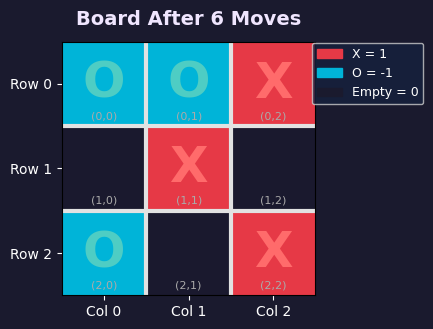

In [10]:
# ─── Cell 7C: Demo Game Sequence with Validation Tests ───────────────────────

print('=' * 55)
print('  🎮 Demo: 5-Move Sequence + Validation Tests')
print('=' * 55)

reset_game()

# Play valid moves
for r, c in [(1,1), (0,0), (0,2), (2,0), (2,2)]:
    place_piece(r, c)

print('─' * 40)
print('🔍 Validation Tests:')

print('\n▶ Overwrite occupied cell (1,1):')
place_piece(1, 1)

print('\n▶ Out of bounds (3, 5):')
place_piece(3, 5)

print('\n▶ Valid move (0, 1):')
place_piece(0, 1)

print('\n🎨 Current board:')
visualize_ttt_board(game_state['board'], 'Board After 6 Moves')

---
## 🧠 Section 8 & 9: Tic-Tac-Toe Game Logic + Winner & Draw Detection

### 🏆 Win Detection Strategy

Sum each line of 3 cells:
- `sum == 3` → all are `1` (X) → **X wins**
- `sum == -3` → all are `-1` (O) → **O wins**
- Board full + no winner → **Draw** (detected via `np.all(board != 0)`)

### 📋 All 8 Lines to Check
| Line | Access Pattern |
|---|---|
| Row 0, 1, 2 | `board[r, :]` |
| Col 0, 1, 2 | `board[:, c]` |
| Main diagonal | `board[[0,1,2], [0,1,2]]` (fancy index) |
| Anti-diagonal | `board[[0,1,2], [2,1,0]]` (fancy index) |

---
## 🧪 Section 10: Testing and Debugging

We test the winner checker with **9 pre-built boards** covering all scenarios:

| Test | Scenario | Expected |
|---|---|---|
| 1-2 | X wins via row | `X` |
| 3-4 | O wins via column | `O` |
| 5 | X wins via main diagonal | `X` |
| 6 | O wins via anti-diagonal | `O` |
| 7 | Draw – board full, no winner | `Draw` |
| 8 | Game ongoing (mid-game) | `Ongoing` |
| 9 | Empty board | `Ongoing` |

In [11]:
# ─── Cell 9A: Comprehensive Test Cases ───────────────────────────────────────

def run_test(name, board_list, expected):
    """Runs one test case and prints PASS/FAIL."""
    board  = np.array(board_list, dtype=int)
    result = check_winner(board)
    status = '✅ PASS' if result == expected else '❌ FAIL'
    print(f'{status} | {name}')
    print(f'         Expected: {expected:>8}  |  Got: {result}')
    return result == expected


print('=' * 60)
print('  🧪 Winner Checker – Test Suite (9 Cases)')
print('=' * 60)

test_cases = [
    ('X wins – Row 0',
     [[ 1,  1,  1], [-1,  0, -1], [ 0,  0,  0]], 'X'),

    ('X wins – Row 2',
     [[-1, -1,  0], [ 0, -1,  0], [ 1,  1,  1]], 'X'),

    ('O wins – Column 1',
     [[ 1, -1,  0], [ 0, -1,  1], [ 0, -1,  0]], 'O'),

    ('O wins – Column 2',
     [[ 1,  0, -1], [ 1,  0, -1], [ 0,  1, -1]], 'O'),

    ('X wins – Main Diagonal',
     [[ 1, -1,  0], [-1,  1,  0], [ 0,  0,  1]], 'X'),

    ('O wins – Anti-Diagonal',
     [[ 1,  1, -1], [ 0, -1,  1], [-1,  0,  0]], 'O'),

    ('Draw – Full Board, No Winner',
     [[ 1, -1,  1], [ 1,  1, -1], [-1,  1, -1]], 'Draw'),

    ('Ongoing – Mid-Game',
     [[ 1,  0,  0], [ 0, -1,  0], [ 0,  0,  1]], 'Ongoing'),

    ('Ongoing – Empty Board',
     [[ 0,  0,  0], [ 0,  0,  0], [ 0,  0,  0]], 'Ongoing'),
]

results = []
for name, board_data, expected in test_cases:
    passed = run_test(name, board_data, expected)
    results.append(passed)
    print()

total  = len(results)
passed = sum(results)
print('=' * 60)
print(f'  🏁 Test Results: {passed}/{total} passed')
if passed == total:
    print('  🎉 All tests PASSED! Winner checker is working.')
else:
    print(f'  ⚠️  {total-passed} test(s) failed.')
print('=' * 60)

  🧪 Winner Checker – Test Suite (9 Cases)
✅ PASS | X wins – Row 0
         Expected:        X  |  Got: X

✅ PASS | X wins – Row 2
         Expected:        X  |  Got: X

✅ PASS | O wins – Column 1
         Expected:        O  |  Got: O

✅ PASS | O wins – Column 2
         Expected:        O  |  Got: O

✅ PASS | X wins – Main Diagonal
         Expected:        X  |  Got: X

✅ PASS | O wins – Anti-Diagonal
         Expected:        O  |  Got: O

✅ PASS | Draw – Full Board, No Winner
         Expected:     Draw  |  Got: Draw

✅ PASS | Ongoing – Mid-Game
         Expected:  Ongoing  |  Got: Ongoing

✅ PASS | Ongoing – Empty Board
         Expected:  Ongoing  |  Got: Ongoing

  🏁 Test Results: 9/9 passed
  🎉 All tests PASSED! Winner checker is working.


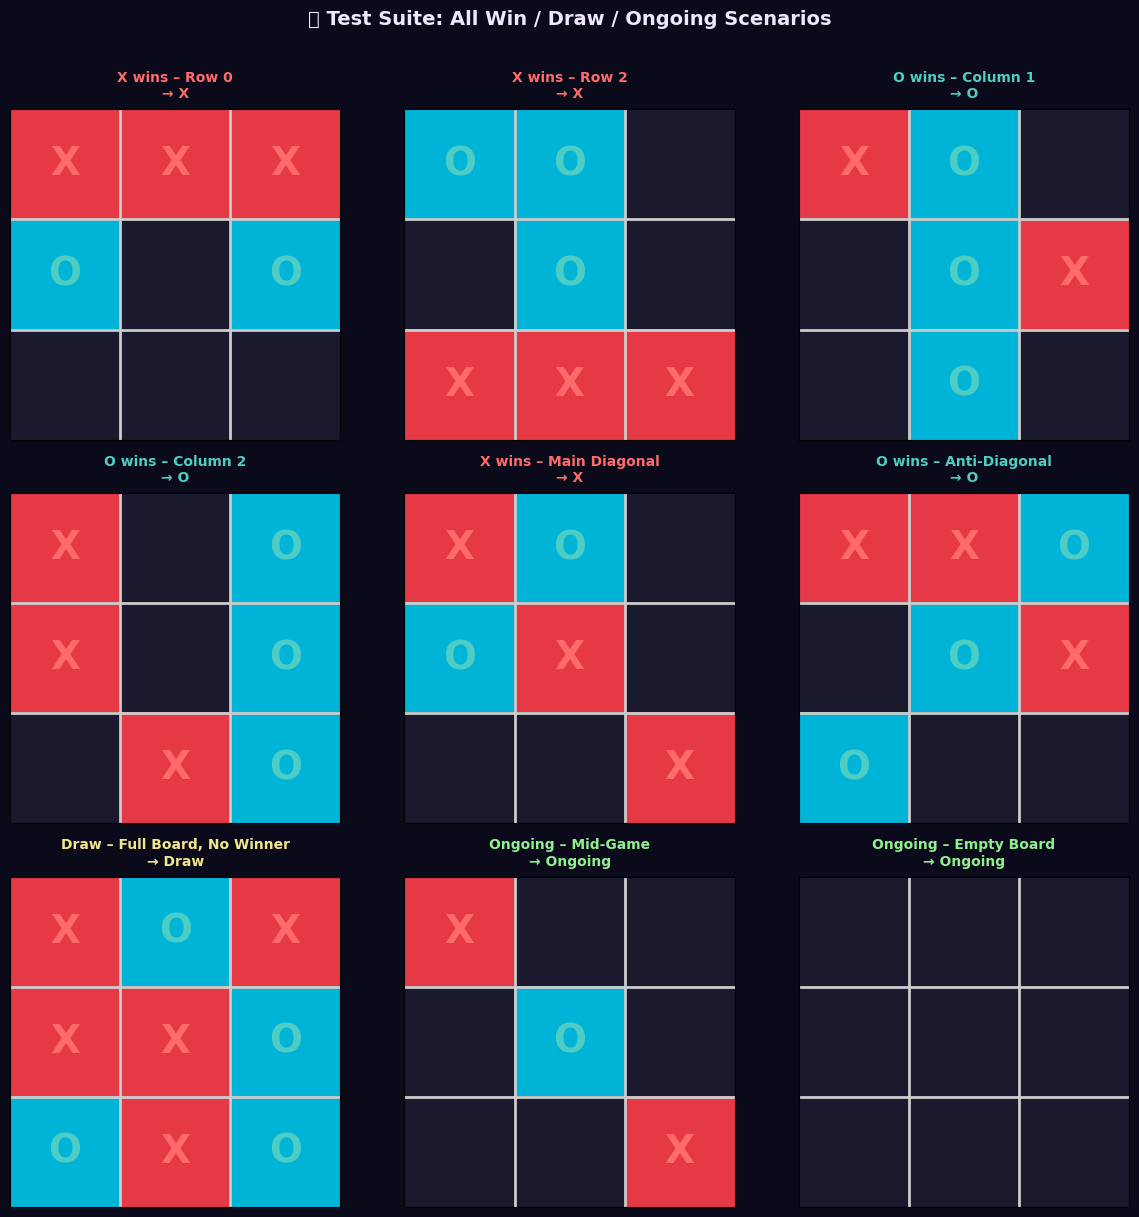

In [12]:
# ─── Cell 9B: Visual Board Showcase of All Test Cases ────────────────────────

def visualize_multiple_boards(board_configs, cols=3):
    """Displays multiple boards side-by-side for comparison."""
    from matplotlib.patches import Patch

    n      = len(board_configs)
    rows_n = (n + cols - 1) // cols

    fig, axes = plt.subplots(rows_n, cols,
                             figsize=(cols * 4, rows_n * 4),
                             facecolor='#0a0a1a')

    axes_flat = axes.flatten() if hasattr(axes, 'flatten') else [axes]

    symbol_map   = {0: '', 1: 'X', -1: 'O'}
    color_map    = {0: '#aaaaaa', 1: '#ff6b6b', -1: '#4ecdc4'}
    result_color = {'X': '#ff6b6b', 'O': '#4ecdc4',
                    'Draw': '#f0e68c', 'Ongoing': '#90ee90'}

    for idx, (board, label) in enumerate(board_configs):
        ax = axes_flat[idx]
        ax.set_facecolor('#16213e')

        result = check_winner(board)
        cmap = mcolors.LinearSegmentedColormap.from_list(
            'ttt2', ['#00b4d8', '#1a1a2e', '#e63946'], N=3)
        ax.imshow(board, cmap=cmap, vmin=-1, vmax=1, aspect='equal')

        for x in [0.5, 1.5]:
            ax.axhline(x, color='#cccccc', linewidth=2)
            ax.axvline(x, color='#cccccc', linewidth=2)

        for r in range(3):
            for c in range(3):
                val = board[r, c]
                sym = symbol_map[val]
                if sym:
                    ax.text(c, r, sym, ha='center', va='center',
                            fontsize=28, fontweight='bold', color=color_map[val])

        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(f'{label}\n→ {result}',
                     color=result_color.get(result, 'white'),
                     fontsize=10, fontweight='bold', pad=8)

    for idx in range(n, len(axes_flat)):
        axes_flat[idx].set_visible(False)

    plt.suptitle('🧪 Test Suite: All Win / Draw / Ongoing Scenarios',
                 color='#f0e6ff', fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()


board_configs = [
    (np.array(bd, dtype=int), nm)
    for nm, bd, _ in test_cases
]
visualize_multiple_boards(board_configs, cols=3)

  🎮 Live Simulation: X wins via Column 0
🔄 Game reset! Fresh empty board.

  ── Fresh Board ──
      Col: 0   1   2
    Row 0: . | . | .
    Row 1: . | . | .
    Row 2: . | . | .

✅ Player X placed at (0,0)  [Move #1]

  ── After X's Move ──
      Col: 0   1   2
    Row 0: X | . | .
    Row 1: . | . | .
    Row 2: . | . | .

✅ Player O placed at (0,1)  [Move #2]

  ── After O's Move ──
      Col: 0   1   2
    Row 0: X | O | .
    Row 1: . | . | .
    Row 2: . | . | .

✅ Player X placed at (1,0)  [Move #3]

  ── After X's Move ──
      Col: 0   1   2
    Row 0: X | O | .
    Row 1: X | . | .
    Row 2: . | . | .

✅ Player O placed at (0,2)  [Move #4]

  ── After O's Move ──
      Col: 0   1   2
    Row 0: X | O | O
    Row 1: X | . | .
    Row 2: . | . | .

✅ Player X placed at (2,0)  [Move #5]
  ┌────────────────────────────┐
  │  🏆 X WINS!                 │
  └────────────────────────────┘

  ── Final Board ──
      Col: 0   1   2
    Row 0: X | O | O
    Row 1: X | . | .
    Row 2: 

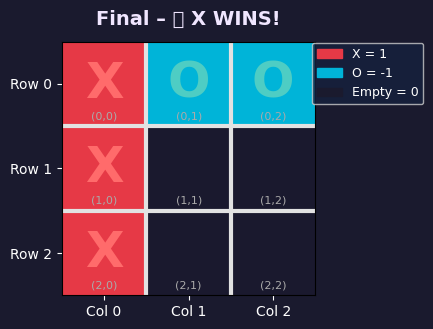


▶ Attempt to play after game over:
🚫 Game over. Call reset_game() to play again.


False

In [13]:
# ─── Cell 9C: Live Game – X Wins via Column 0 ────────────────────────────────

print('=' * 55)
print('  🎮 Live Simulation: X wins via Column 0')
print('=' * 55)

reset_game()

for r, c in [(0,0), (0,1), (1,0), (0,2), (2,0)]:
    place_piece(r, c)

print('\n▶ Attempt to play after game over:')
place_piece(2, 2)

  🤝 Live Simulation: Draw
🔄 Game reset! Fresh empty board.

  ── Fresh Board ──
      Col: 0   1   2
    Row 0: . | . | .
    Row 1: . | . | .
    Row 2: . | . | .

✅ Player X placed at (0,0)  [Move #1]

  ── After X's Move ──
      Col: 0   1   2
    Row 0: X | . | .
    Row 1: . | . | .
    Row 2: . | . | .

✅ Player O placed at (0,1)  [Move #2]

  ── After O's Move ──
      Col: 0   1   2
    Row 0: X | O | .
    Row 1: . | . | .
    Row 2: . | . | .

✅ Player X placed at (0,2)  [Move #3]

  ── After X's Move ──
      Col: 0   1   2
    Row 0: X | O | X
    Row 1: . | . | .
    Row 2: . | . | .

✅ Player O placed at (1,1)  [Move #4]

  ── After O's Move ──
      Col: 0   1   2
    Row 0: X | O | X
    Row 1: . | O | .
    Row 2: . | . | .

✅ Player X placed at (1,0)  [Move #5]

  ── After X's Move ──
      Col: 0   1   2
    Row 0: X | O | X
    Row 1: X | O | .
    Row 2: . | . | .

✅ Player O placed at (1,2)  [Move #6]

  ── After O's Move ──
      Col: 0   1   2
    Row 0: X | O 

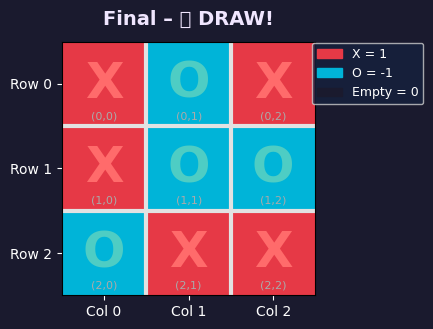

✅ Draw simulation complete!


In [14]:
# ─── Cell 9D: Live Game – Draw Simulation ────────────────────────────────────

print('=' * 55)
print('  🤝 Live Simulation: Draw')
print('=' * 55)

reset_game()

# 9 moves → board full → no winner
for r, c in [(0,0),(0,1),(0,2),(1,1),(1,0),(1,2),(2,1),(2,0),(2,2)]:
    place_piece(r, c)

print('✅ Draw simulation complete!')

---
## 🐛 Common Errors and How to Fix Them

| # | Error | Cause | Fix |
|---|---|---|---|
| 1 | `IndexError: index 3 is out of bounds` | Row/col must be 0–2 | Validate before indexing |
| 2 | `ValueError: setting element with a sequence` | Mismatched nested list lengths | Ensure all rows same length |
| 3 | Board shows floats (0.0, 1.0) | Forgot `dtype=int` | Add `dtype=int` to `np.zeros()` |
| 4 | Win not detected | Wrong sum threshold | Check X=1, O=-1, sum=±3 |
| 5 | `np.fliplr` fails | Applied to 1D array | Use `[::-1]` for 1D arrays |

In [15]:
# ─── Cell 10: Common Errors Demo and Fixes ───────────────────────────────────

print('=' * 55)
print('  🐛 Common Errors & Fixes')
print('=' * 55)

# ── Error 1: Float vs Int ─────────────────────────────────────────────────────
print('\n❌ Error 1: np.zeros without dtype=int gives floats')
float_board = np.zeros((3, 3))             # Default: float64
print(f'   dtype: {float_board.dtype}  |  values: {float_board[0]}')
print('✅ Fix: np.zeros((3,3), dtype=int)')
int_board = np.zeros((3, 3), dtype=int)   # Correct: int64
print(f'   dtype: {int_board.dtype}  |  values: {int_board[0]}')

# ── Error 2: np.fliplr on 1D array ───────────────────────────────────────────
print('\n❌ Error 2: np.fliplr on 1D array')
try:
    np.fliplr(np.array([1, 0, -1]))        # Needs 2D!
except ValueError as e:
    print(f'   ValueError: {e}')
print('✅ Fix: Use [::-1] to reverse a 1D array')
print(f'   np.array([1,0,-1])[::-1] = {np.array([1,0,-1])[::-1]}')

# ── Error 3: Index out of bounds ─────────────────────────────────────────────
print('\n❌ Error 3: board[3,0] on a 3×3 board')
try:
    np.zeros((3,3), dtype=int)[3, 0]       # Index 3 doesn't exist
except IndexError as e:
    print(f'   IndexError: {e}')
print('✅ Fix: Always check bounds first')
print('   if row in np.arange(3) and col in np.arange(3): ...')

# ── Error 4: Silent cell overwrite ───────────────────────────────────────────
print('\n❌ Error 4: Overwriting occupied cell without a check')
b = np.array([[1,0,0],[0,0,0],[0,0,0]])
print(f'   Before: board[0,0] = {b[0,0]}  (X)')
b[0,0] = -1   # Silently replaces X with O!
print(f'   After:  board[0,0] = {b[0,0]}  (X was silently replaced by O!)')
print('✅ Fix: Check board[row,col] == 0 before placing')

print('\n✅ Error demonstration complete!')

  🐛 Common Errors & Fixes

❌ Error 1: np.zeros without dtype=int gives floats
   dtype: float64  |  values: [0. 0. 0.]
✅ Fix: np.zeros((3,3), dtype=int)
   dtype: int64  |  values: [0 0 0]

❌ Error 2: np.fliplr on 1D array
   ValueError: Input must be >= 2-d.
✅ Fix: Use [::-1] to reverse a 1D array
   np.array([1,0,-1])[::-1] = [-1  0  1]

❌ Error 3: board[3,0] on a 3×3 board
   IndexError: index 3 is out of bounds for axis 0 with size 3
✅ Fix: Always check bounds first
   if row in np.arange(3) and col in np.arange(3): ...

❌ Error 4: Overwriting occupied cell without a check
   Before: board[0,0] = 1  (X)
   After:  board[0,0] = -1  (X was silently replaced by O!)
✅ Fix: Check board[row,col] == 0 before placing

✅ Error demonstration complete!


---
## 🎓 Section 11: Project Conclusion

### 🏆 What You Built
Congratulations! You built a **complete Game Board & Pattern Generator Toolkit** using Python and NumPy.

### ✅ NumPy Concepts Mastered

| NumPy Concept | Used For |
|---|---|
| `np.zeros((3,3), dtype=int)` | Empty Tic-Tac-Toe board |
| `np.ones()` | Reference grids |
| `np.full()` | Custom-value boards |
| `np.eye(n)` | Diagonal pattern generator |
| `np.arange(3)` | Fancy indexing index arrays |
| `np.array(nested_list)` | Board setup from lists |
| `board[::2, ::2]` | Checkerboard stepped slicing |
| `board[rows, cols]` | Multi-cell fancy indexing |
| `np.fliplr()` | Anti-diagonal pattern |
| `np.all(board != 0)` | Draw detection |
| `np.sum(line)` | Win detection math |

### 🚀 Ideas for Next Steps
- Add an **interactive input loop** for two human players
- Build a simple **AI opponent** using the Minimax algorithm
- Extend to **5-in-a-row (Gomoku)** using the same NumPy concepts
- Add **ipywidgets** for clickable board interaction in Colab

---
## 📄 Section 12: Resume Description

---

### 🔹 Short Version (1 line)
> *Created a NumPy grid toolkit generating game boards with `np.eye`, stepped slicing, and fancy indexing, plus a Tic-Tac-Toe win/draw checker.*

---

### 🔹 Medium Version (bullets)

**Game Board & Pattern Generator Toolkit** | Python · NumPy · Matplotlib · Google Colab

- Built a Tic-Tac-Toe board generator using `np.zeros()`, nested-list-to-array conversion, and row/column indexing
- Generated an 8×8 checkerboard pattern using NumPy stepped slicing (`board[::2, ::2]` and `board[1::2, 1::2]`)
- Created diagonal and anti-diagonal patterns using `np.eye()` and `np.fliplr()`
- Implemented move validation and piece placement with fancy indexing and bounds checking
- Developed a win/draw detection system checking all 8 board lines using `np.sum()`, `np.all()`, and conditional logic
- Visualized all boards and patterns with Matplotlib using custom color maps and dark-mode design

---

### 🔹 ATS Keywords
`Python` · `NumPy` · `Matplotlib` · `Array Indexing` · `Fancy Indexing`
`Stepped Slicing` · `Game Logic` · `Google Colab` · `Data Structures` · `Algorithm Design`